<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# The Central Limit Theorem, Hypothesis Testing, and Confidence Intervals

_Author: Tim Book_

---

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# CLT Demo

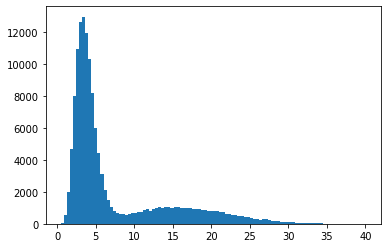

In [2]:
# Weird data... definitely not normal!
xs = np.load('data/strange-data.npy')
plt.hist(xs, bins=100);

In [3]:
# Let's take 100k samples each of size 100. You can play with this if you'd like.
n = 100
N = 100_000

samples = [np.random.choice(xs, n) for _ in range(N)]
means = [np.mean(smp) for smp in samples]

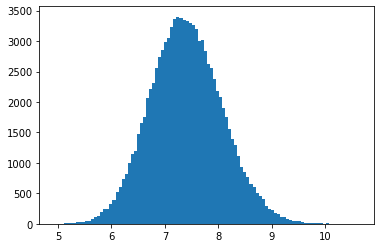

In [4]:
# HOLY MOLY!!! The CLT really is incredible.
plt.hist(means, bins=100);

## Hypothesis Testing: Blood Pressure Data

In [5]:
# Read in the data
bp = pd.read_csv('data/blood-pressure.csv')
bp.head()

,bp,group
0,166,control
1,165,control
2,120,control
3,94,control
4,104,control


In [6]:
# What is the average blood pressure by group?
bp.groupby('group').bp.agg(['count', 'mean', 'std'])

,count,mean,std
group,,,
control,50,121.38,28.390060
treatment,50,111.56,23.272266


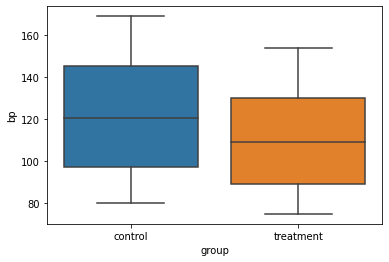

In [7]:
# Make a viz that illustrates the distributions of
# treatment vs control
sns.boxplot(x='group', y='bp', data=bp);

## The Two-Sample _t_-test

In this example, we're concerned with determining if people who received the new heart medication (the treatment group) have a lower blood pressure than those who received the old medication (the control group). 

## Let's write hypotheses...

$$H_0: \mu_{trt} - \mu_{ctrl} = 0$$
$$H_A: \mu_{trt} - \mu_{ctrl} < 0$$

## Next...

Let's figure out what kind of hypothesis test to run?

In [8]:
# Create two separate vectors of blood pressure
trt = bp.loc[bp.group == 'treatment', 'bp']
ctrl = bp.loc[bp.group == 'control', 'bp']

In [9]:
# And let's carry out the test!
stats.ttest_ind(trt, ctrl, equal_var=False)

Ttest_indResult(statistic=-1.8915462966190273, pvalue=0.06161817112302221)

But wait... by default, we're conducting "two-sided" hypothesis tests. That is, our default alternative hypothesis is:

$$H_A: \mu_{trt} - \mu_{ctrl} \ne 0$$

The solution here is to _half_ the _p_-value to get a one-tailed result.

In [10]:
tstat, pval = stats.ttest_ind(trt, ctrl, equal_var=False)

In [11]:
pval / 2

0.030809085561511105

## Interpet!
Ok, we've got a _p_-value! Let's interpret it here:

Since our _p_-value is low, we reject our null hypothesis and conclude that the true mean blood pressure of patients in our treatment group is less than the blood pressure of those in our control group.

# The ANOVA Test

In [12]:
# Read data
soap = pd.read_csv("data/soap.csv")
soap

,cube,level,pre,post
0,1,1,13.14,13.44
1,2,1,13.17,13.27
2,3,1,13.17,13.31
3,4,1,13.17,12.77
4,5,2,13.03,10.40
5,6,2,13.18,10.57
6,7,2,13.12,10.71
7,8,2,13.19,10.04
8,9,3,13.14,11.28
9,10,3,13.19,11.16


In [13]:
# Calculate weight loss
soap["wloss"] = soap["pre"] - soap["post"]
soap

,cube,level,pre,post,wloss
0,1,1,13.14,13.44,-0.30
1,2,1,13.17,13.27,-0.10
2,3,1,13.17,13.31,-0.14
3,4,1,13.17,12.77,0.40
4,5,2,13.03,10.40,2.63
5,6,2,13.18,10.57,2.61
6,7,2,13.12,10.71,2.41
7,8,2,13.19,10.04,3.15
8,9,3,13.14,11.28,1.86
9,10,3,13.19,11.16,2.03


In [14]:
# Some EDA
soap.groupby("level")["wloss"].mean()

level
1   -0.0350
2    2.7000
3    1.9925
Name: wloss, dtype: float64

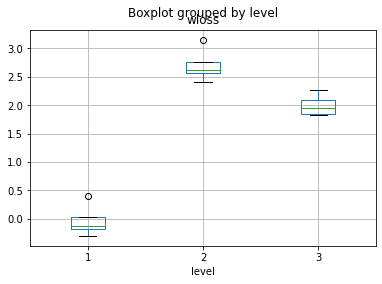

In [15]:
soap.boxplot(column="wloss", by="level");

## ANOVA Test of Soap Weight Loss
What are our hypotheses?

$$
H_0: \mu_1 = \mu_2 = \mu_3
$$

$$
H_A: \text{At least one } \mu_i \ne \mu_j \text{ for some } i \ne j
$$

In [16]:
# Mindless SciPy one-way ANOVA test
soap1 = soap.loc[soap['level'] == 1, "wloss"]
soap2 = soap.loc[soap['level'] == 2, "wloss"]
soap3 = soap.loc[soap['level'] == 3, "wloss"]
stats.f_oneway(soap1, soap2, soap3)

F_onewayResult(statistic=104.45124716553275, pvalue=5.914409422315586e-07)

In [17]:
# Imports from statsmodels
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

In [18]:
# statsmodels follows the R pattern of using "formulas" to specify a model
# In order to specify a variable is categorical, use the C() function.
model = ols("wloss ~ C(level)", soap).fit()

In [19]:
# Can summarize this just like other statsmodels models
model.summary()

/home/tim/.local/lib/python3.6/site-packages/scipy/stats/stats.py:1604: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=12
  "anyway, n=%i" % int(n))


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  wloss   R-squared:                       0.959
Model:                            OLS   Adj. R-squared:                  0.950
Method:                 Least Squares   F-statistic:                     104.5
Date:                Sun, 24 Sep 2023   Prob (F-statistic):           5.91e-07
Time:                        21:47:44   Log-Likelihood:               0.068908
No. Observations:                  12   AIC:                             5.862
Df Residuals:                       9   BIC:                             7.317
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -0.0350      0.139     -0.252      0.807      -0.349       0.279
C(level)[T.2]     2.7350      0.196     13.923      0.000       2.291       3.179
C(level)[T.3]     2.0275      0.196     10.321      0.000       1.583       2.472
==============================================================================
Omnibus:                        2.324   Durbin-Watson:                   2.578
Prob(Omnibus):                  0.313   Jarque-Bera (JB):                1.594
Skew:                           0.836   Prob(JB):                        0.451
Kurtosis:                       2.372   Cond. No.                         3.73
==============================================================================

Warnings:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [20]:
# Here's where the magic happens...
# Let's look at this and go back to the deck.
anova_lm(model)

,df,sum_sq,mean_sq,F,PR(>F)
C(level),2.0,16.122050,8.061025,104.451247,5.914409e-07
Residual,9.0,0.694575,0.077175,NaN,NaN


## A bigger, more complex ANOVA
_(The two-way ANOVA)_

In [21]:
# Reaction time data
react = pd.read_csv("data/reaction.csv")
print(react)

    cue  wait  reaction
0     1     1     0.204
1     1     1     0.170
2     1     1     0.181
3     1     2     0.167
4     1     2     0.182
5     1     2     0.187
6     1     3     0.202
7     1     3     0.198
8     1     3     0.236
9     2     1     0.257
10    2     1     0.279
11    2     1     0.269
12    2     2     0.283
13    2     2     0.235
14    2     2     0.260
15    2     3     0.256
16    2     3     0.281
17    2     3     0.258


In [22]:
# statsmodels formula
# The * operator in formulae means "both main effects and interaction terms"
fml = "reaction ~ C(cue)*C(wait)"

# Fit model
model = ols(fml, react).fit()

# Again - we can see the summary
model.summary()

/home/tim/.local/lib/python3.6/site-packages/scipy/stats/stats.py:1604: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=18
  "anyway, n=%i" % int(n))


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               reaction   R-squared:                       0.880
Model:                            OLS   Adj. R-squared:                  0.831
Method:                 Least Squares   F-statistic:                     17.66
Date:                Sun, 24 Sep 2023   Prob (F-statistic):           3.66e-05
Time:                        21:47:44   Log-Likelihood:                 51.440
No. Observations:                  18   AIC:                            -90.88
Df Residuals:                      12   BIC:                            -85.54
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
============================================================================================
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                    0.1850      0.010     18.838      0.000       0.164       0.206
C(cue)[T.2]                  0.0833      0.014      6.000      0.000       0.053       0.114
C(wait)[T.2]                -0.0063      0.014     -0.456      0.657      -0.037       0.024
C(wait)[T.3]                 0.0270      0.014      1.944      0.076      -0.003       0.057
C(cue)[T.2]:C(wait)[T.2]    -0.0027      0.020     -0.136      0.894      -0.045       0.040
C(cue)[T.2]:C(wait)[T.3]    -0.0303      0.020     -1.544      0.148      -0.073       0.012
==============================================================================
Omnibus:                        1.340   Durbin-Watson:                   2.857
Prob(Omnibus):                  0.512   Jarque-Bera (JB):                0.978
Skew:                           0.294   Prob(JB):                        0.613
Kurtosis:                       2.020   Cond. No.                         9.77
==============================================================================

Warnings:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [23]:
# But the ANOVA table is the good stuff
anova_lm(model)

,df,sum_sq,mean_sq,F,PR(>F)
C(cue),1.0,0.023544,0.023544,81.375000,0.000001
C(wait),2.0,0.001158,0.000579,2.001344,0.177799
C(cue):C(wait),2.0,0.000846,0.000423,1.462558,0.270135
Residual,12.0,0.003472,0.000289,NaN,NaN


# Confidence Intervals

In [24]:
ff = pd.read_csv('data/fast-food-orders.csv')
ff.head()

,order_num,order_price
0,1,13.635444
1,2,19.045970
2,3,12.251006
3,4,12.361692
4,5,12.498826


#### For a single mean: A one-sample mean $t$-interval
Because the CLT is an approximation, we don't technically use the full normal distribution. Instead, we use the $t$-distribution, which is very similar. To carry out a $t$-interval, we need three things:

1. The sample mean
1. The sample standard **error**, which is just $s / \sqrt{n}$
1. The "degrees of freedom" (in this case, it's simply $n - 1$)

In [25]:
n = ff.shape[0]
xbar = ff.order_price.mean()

# Statsmodels gives us a shorcut for standard error of the mean
se = stats.sem(ff.order_price)

stats.t.interval(0.95, df=(n - 1), loc=xbar, scale=se)

(15.739143078268667, 19.869846855091808)

## Interpret!

Interpret this confidence interval below:

> We are 95% confident that the true population mean fast food order is between \\$15.74 and \\$19.87.